# Notebook 03: EDA + Feature Engineering

Discover factors associated with Instagram reach.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("../data/processed/processed_data.csv")
os.makedirs("../reports/figures", exist_ok=True)

## Overall Performance (Distributions)

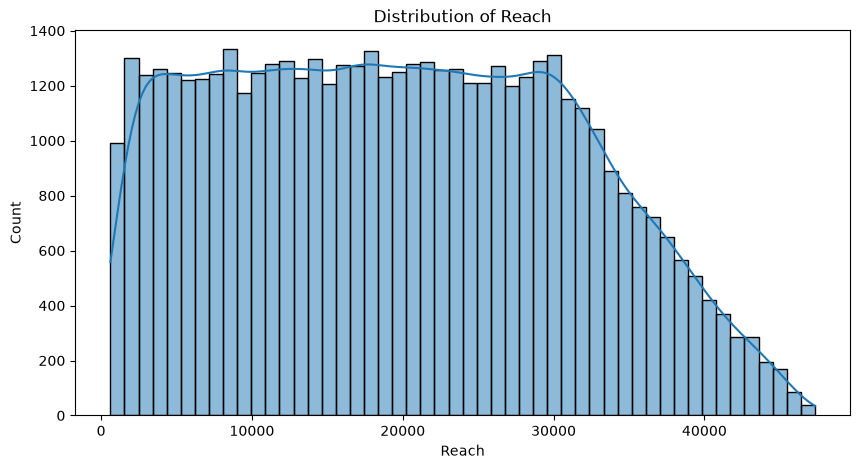

In [2]:
plt.figure(figsize=(10,5))
sns.histplot(df["Reach"], bins=50, kde=True)
plt.title("Distribution of Reach")
plt.savefig("../reports/figures/reach_distribution.png")
plt.show()

## Posting Day Analysis

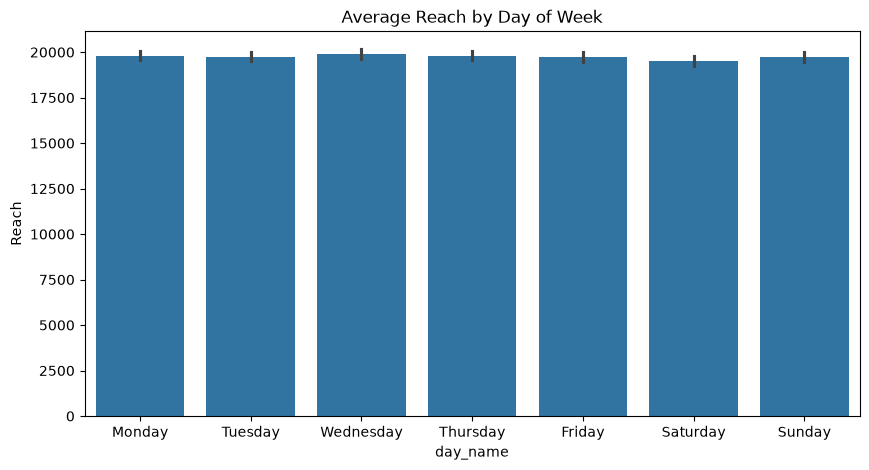

In [3]:
plt.figure(figsize=(10,5))
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.barplot(x="day_name", y="Reach", data=df, order=order)
plt.title("Average Reach by Day of Week")
plt.savefig("../reports/figures/reach_by_day.png")
plt.show()

## Content Analysis

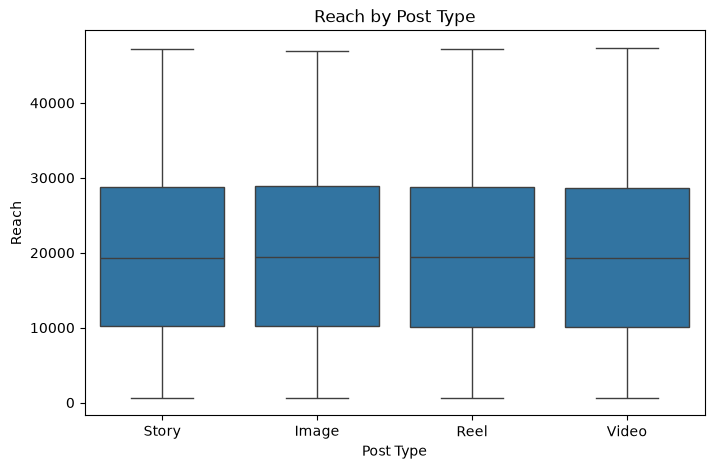

In [4]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Post Type", y="Reach", data=df)
plt.title("Reach by Post Type")
plt.savefig("../reports/figures/reach_by_post_type.png")
plt.show()

## Hashtag Analysis

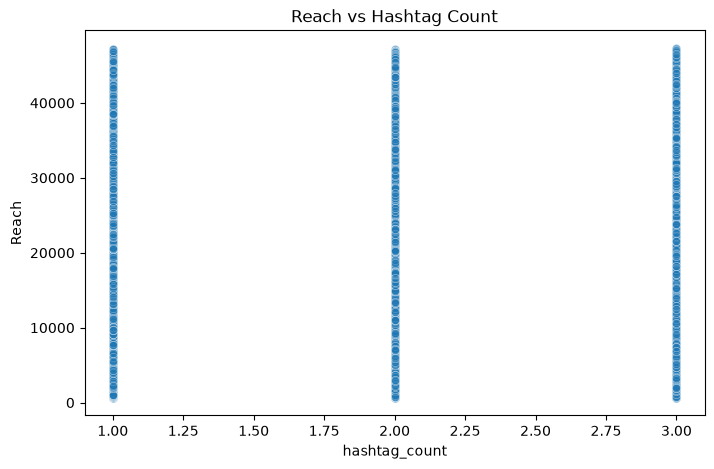

In [5]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="hashtag_count", y="Reach", data=df, alpha=0.5)
plt.title("Reach vs Hashtag Count")
plt.savefig("../reports/figures/reach_vs_hashtags.png")
plt.show()

## Engagement Analysis (Custom Metric)

In [6]:
df["Engagement Rate"] = ((df["Likes"] + df["Comments"] + df["Shares"] + df["Saves"]) / df["Reach"]) * 100
print("Average Engagement Rate:", df["Engagement Rate"].mean(), "%")

Average Engagement Rate: 18.535169056133142 %


## Correlation Analysis

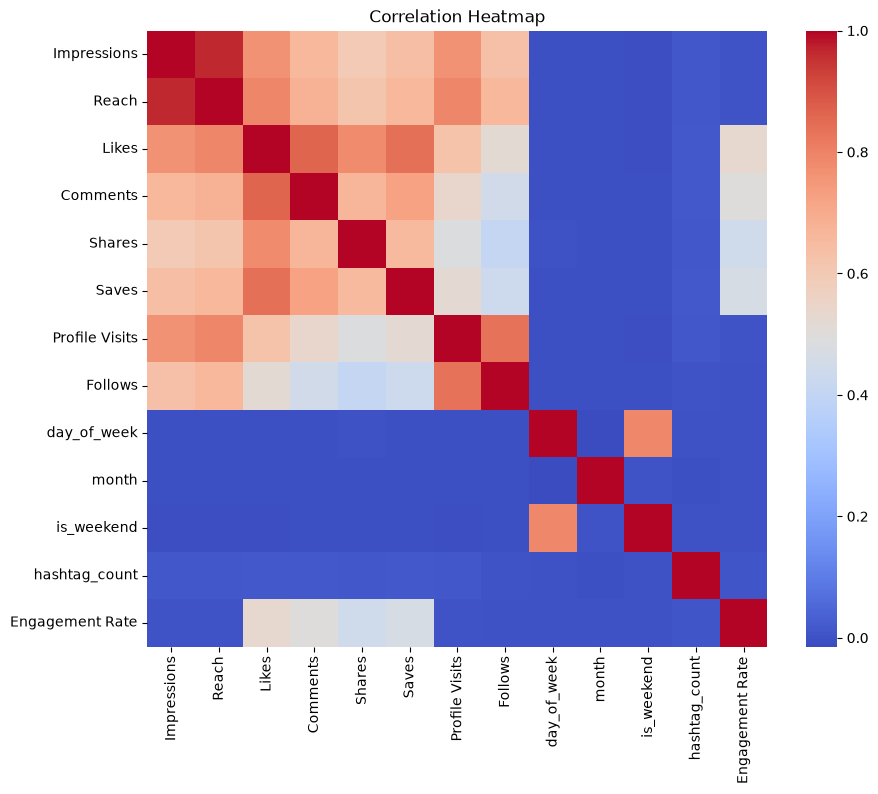

In [7]:
numeric_cols = df.select_dtypes(include=["number"]).columns
plt.figure(figsize=(10,8))
sns.heatmap(df[numeric_cols].corr(), annot=False, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("../reports/figures/correlation_heatmap.png")
plt.show()

## Feature Engineering Pipeline
We will select only pre-publication features to prevent data leakage. 

Target: `Reach`
Features: `day_of_week`, `is_weekend`, `month`, `Post Type`, `Campaign Type`, `hashtag_count`

In [8]:
features = ["day_of_week", "is_weekend", "month", "Post Type", "Campaign Type", "hashtag_count"]
target = "Reach"
model_data = df[features + [target]].dropna()
model_data.to_csv("../data/processed/model_data.csv", index=False)
print("Model data shape:", model_data.shape)

Model data shape: (50000, 7)
